In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.feature_selection import SelectKBest,chi2
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
df=pd.read_csv('online_food_delivery.csv')

In [ ]:
df.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [ ]:
df.shape

(388, 14)

In [ ]:
#select features
features = [
    'Age',
    'Gender',
    'Marital Status',
    'Occupation',
    'Monthly Income',
    'Educational Qualifications',
    'Family size'
]


In [ ]:
x=df[features]
y=df['Customer Type']

In [ ]:
#split dataset
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,stratify=y
)

In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Marital Status,0
Occupation,0
Monthly Income,0
Educational Qualifications,0
Family size,0
Customer Type,0
latitude,0
longitude,0


In [ ]:
df['Educational Qualifications'].value_counts()

,count
Educational Qualifications,
Graduate,177
Post Graduate,174
Ph.D,23
School,12
Uneducated,2


In [ ]:
df['Monthly Income'].value_counts()

,count
Monthly Income,
No Income,187
25001 to 50000,69
More than 50000,62
10001 to 25000,45
Below Rs.10000,25


Customer Type
Regular     218
Frequent    146
New          24
Name: count, dtype: int64


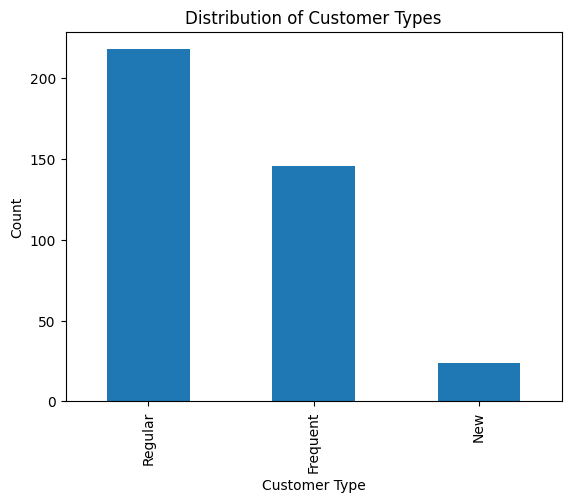

In [ ]:
#EDA
print(y.value_counts())

y.value_counts().plot(kind='bar')
plt.title('Distribution of Customer Types')
plt.xlabel('Customer Type')
plt.ylabel('Count')
plt.show()

In [ ]:
ordinal_features = [
    'Educational Qualifications',
    'Monthly Income'
]

nominal_features = [
    'Gender',
    'Marital Status',
    'Occupation'
]

numeric_features = [
    'Age',
    'Family size'
]

education_order = [
    'Uneducated',
    'School',
    'Graduate',
    'Post Graduate',
    'Ph.D'
]

income_order = [
    'No Income',
    'Below Rs.10000',
    '10001 to 25000',
    '25001 to 50000',
    'More than 50000'
]

In [ ]:
ordinal_encoder = OrdinalEncoder(
    categories=[education_order, income_order],
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'ordinal',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', ordinal_encoder)
            ]),
            ordinal_features
        ),
        (
            'nominal',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))
            ]),
            nominal_features
        ),
        (
            'numeric',
            SimpleImputer(strategy='median'),
            numeric_features
        )
    ]
)

In [ ]:
#train the complete data
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Frequent       1.00      1.00      1.00        29
         New       1.00      1.00      1.00         5
     Regular       1.00      1.00      1.00        44

    accuracy                           1.00        78
   macro avg       1.00      1.00      1.00        78
weighted avg       1.00      1.00      1.00        78



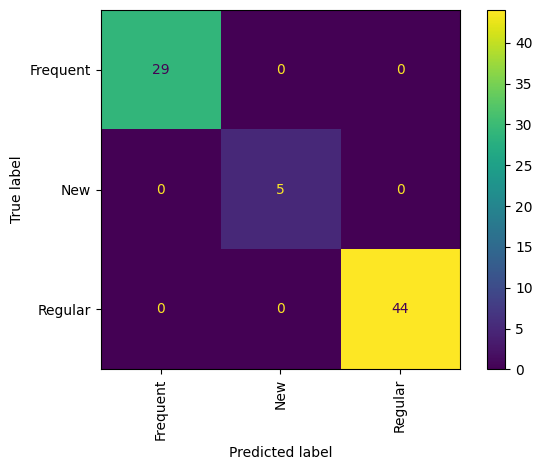

In [ ]:
#evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation='vertical'
)

plt.tight_layout()
plt.show()

In [ ]:
print(pd.crosstab(df['Customer Type'], df['Output']))
print(pd.crosstab(df['Customer Type'], df['Feedback']))

Output         No  Yes
Customer Type         
Frequent       34  112
New             7   17
Regular        46  172
Feedback       Negative   Positive
Customer Type                     
Frequent              26       120
New                    6        18
Regular               39       179


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    x,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro']
)

print("Fold accuracies:", scores['test_accuracy'])
print("Mean CV accuracy:", scores['test_accuracy'].mean())
print("Mean CV Macro F1:", scores['test_f1_macro'].mean())


Fold accuracies: [1.         1.         0.98717949 1.         1.        ]
Mean CV accuracy: 0.9974358974358974
Mean CV Macro F1: 0.9918435289221806


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, classifier in models.items():
    pipe = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', classifier)
    ])

    scores = cross_validate(
        pipe,
        x,
        y,
        cv=cv,
        scoring=['accuracy', 'f1_macro']
    )

    results.append({
        'Model': name,
        'Mean Accuracy': scores['test_accuracy'].mean(),
        'Mean Macro F1': scores['test_f1_macro'].mean()
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values('Mean Macro F1', ascending=False))

                 Model  Mean Accuracy  Mean Macro F1
1        Decision Tree       1.000000       1.000000
0  Logistic Regression       0.997436       0.991844
2        Random Forest       0.979354       0.935171


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

for depth in [1, 2, 3, 4, 5, None]:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_validate(
        pipe,
        x,
        y,
        cv=cv,
        scoring=['accuracy', 'f1_macro']
    )

    print(
        f"Depth={depth}, "
        f"Accuracy={scores['test_accuracy'].mean():.4f}, "
        f"Macro F1={scores['test_f1_macro'].mean():.4f}"
    )

Depth=1, Accuracy=0.9382, Macro F1=0.6493
Depth=2, Accuracy=1.0000, Macro F1=1.0000
Depth=3, Accuracy=1.0000, Macro F1=1.0000
Depth=4, Accuracy=1.0000, Macro F1=1.0000
Depth=5, Accuracy=1.0000, Macro F1=1.0000
Depth=None, Accuracy=1.0000, Macro F1=1.0000


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=2, random_state=42))
])

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Test Accuracy: 1.0

Confusion Matrix:
 [[29  0  0]
 [ 0  5  0]
 [ 0  0 44]]

Classification Report:
               precision    recall  f1-score   support

    Frequent       1.00      1.00      1.00        29
         New       1.00      1.00      1.00         5
     Regular       1.00      1.00      1.00        44

    accuracy                           1.00        78
   macro avg       1.00      1.00      1.00        78
weighted avg       1.00      1.00      1.00        78



# Conclusion

In this project, I built a machine learning classification model to predict customer types (Frequent, New, and Regular) using demographic and socioeconomic features.

I performed data cleaning, exploratory data analysis (EDA), feature preprocessing, and compared Logistic Regression, Decision Tree, and Random Forest models using 5-fold cross-validation.

The Decision Tree classifier with `max_depth=2` achieved the best cross-validation results, with 100% accuracy and a macro F1-score of 1.00. It also achieved 100% accuracy on the test dataset of 78 records.

The dataset contains only 388 records, so the results should be interpreted carefully. Further testing on an independent dataset is needed to check how well the model performs on new customers.